<div style="box-sizing:border-box;max-width:100%;margin:0 0 8px;padding:4px 0;color:inherit;line-height:1.35;"><img src="https://thetahat.ru/images/logo_thetahat.png" alt="ThetaHat" style="display:block!important;width:52px!important;max-width:52px!important;height:auto!important;margin:0 0 9px 0!important;padding:0!important;"><div style="display:flex;align-items:center;justify-content:space-between;flex-wrap:wrap;gap:8px 12px;"><span style="min-width:0;color:inherit;font-size:12px;font-weight:700;letter-spacing:0.055em;text-transform:uppercase;"><a href="https://thetahat.ru/courses/ysda-group" style="color:inherit;text-decoration:none;">Школа анализа данных</a>&nbsp;·&nbsp;Машинное обучение</span></div></div>

<h2><span style="display:block;box-sizing:border-box;max-width:100%;padding:16px 22px 17px;border-radius:14px;background:linear-gradient(135deg,#D4470E 0%,#C7324E 50%,#B316B8 100%);color:#FFFFFF;line-height:1.15;font-weight:500;">Решающие деревья</span></h2>

В данном ноутбуке мы познакомимся с решающими деревьями. Научимся настраивать их гиперпараметры и поймём, в каких задачах их лучше применять.

In [1]:
from functools import partial
from typing import Callable, Tuple

import graphviz
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import HTML
from sklearn import datasets
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    accuracy_score,
    mean_absolute_error,
    mean_absolute_percentage_error,
    mean_squared_error,
    r2_score,
)
from sklearn.model_selection import train_test_split
from sklearn.tree import (
    DecisionTreeClassifier,
    DecisionTreeRegressor,
    export_graphviz,
)

from notebook_trees_tools import (
    animate_decision_surface,
    calc_metrics,
    get_meshgrid,
    highlight_best,
    plot_classification_dependence,
    plot_decision_surface,
    plot_dependence,
    plot_regression_results,
    visualize_metric_df,
)

sns.set("notebook", style="whitegrid", font_scale=1.3, palette="colorblind")
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

## <span style="display:inline-block;padding:2px 8px;border-radius:999px;background:linear-gradient(135deg, #C7480B 0%, #B52D59 54%, #A617B3 100%);color:#FFFFFF;font-size:0.78em;vertical-align:0.08em;">1</span> <span style="color:inherit;">Введение</span>

### <span style="display:inline-block;padding:2px 8px;border-radius:999px;background:linear-gradient(135deg, #C7480B 0%, #B52D59 54%, #A617B3 100%);color:#FFFFFF;font-size:0.78em;vertical-align:0.08em;">1.1</span> <span style="color:inherit;">Оценка энергоэффективности зданий</span>

[**Energy Efficiency**](https://archive.ics.uci.edu/dataset/242/energy+efficiency) &mdash; датасет содержит сведения о 768 моделях жилых зданий, сгенерированных с помощью программного обеспечения Ecotect. Перед нами стоит задача анализа их энергетической эффективности. Цель — предсказать, сколько энергии потребуется зданию для **отопления** и **охлаждения**, исходя из его геометрических и строительных характеристик.

Для каждого здания указаны восемь числовых признаков, описывающих его архитектурные характеристики:
1. `Relative Compactness`. Относительная компактность здания &mdash; оценка его компактности от 0 до 1
2. `Surface Area`. Площадь поверхности (в м²)
3. `Wall Area`. Площадь стен (в м²)
4. `Roof Area`. Площадь крыши (в м²)
5. `Overall Height`. Высота здания (в м)
6. `Orientation`. Ориентация &mdash; от 2 до 5, где число определяет сторону света, на которую выходит основное количество остекления.
7. `Glazing Area`. Площадь остекления (в м²)
8. `Glazing Area Distribution`. Распределение остекления &mdash; от 0 до 4, где число определяет фиксированный тип остекления, например, окна выходят на юг или окна выходят на две стороны света.

Целевыми переменными являются две величины: `Heating Load` (нагрузка на отопление) и `Cooling Load` (нагрузка на охлаждение). Обе переменные непрерывны и измеряются в кВт·ч/м².

Наша задача будет в предсказании `Cooling Load`.



In [2]:
# Загрузим библиотеку с датасетами
!pip install ucimlrepo


[notice] A new release of pip is available: 26.0.1 -> 26.2.2
[notice] To update, run: pip install --upgrade pip


In [3]:
from ucimlrepo import fetch_ucirepo

energy = fetch_ucirepo(id=242)

energy_X = energy.data.features
energy_y = energy.data.targets

energy_X.head()

,X1,X2,X3,X4,X5,X6,X7,X8
0,0.98,514.5,294.0,110.25,7.0,2,0.0,0
1,0.98,514.5,294.0,110.25,7.0,3,0.0,0
2,0.98,514.5,294.0,110.25,7.0,4,0.0,0
3,0.98,514.5,294.0,110.25,7.0,5,0.0,0
4,0.90,563.5,318.5,122.50,7.0,2,0.0,0


In [4]:
energy_y = energy_y["Y2"]  # берём только Y2 (Cooling Load)
energy_y.head()

0    21.33
1    21.33
2    21.33
3    21.33
4    28.28
Name: Y2, dtype: float64

### <span style="display:inline-block;padding:2px 8px;border-radius:999px;background:linear-gradient(135deg, #C7480B 0%, #B52D59 54%, #A617B3 100%);color:#FFFFFF;font-size:0.78em;vertical-align:0.08em;">1.2</span> <span style="color:inherit;">Предобработка данных</span>

Данные представлены в неудобном формате. Сделаем удобные имена у признаков

In [5]:
def find_name(old_name):
    for _, row in energy.variables.iterrows():
        if row["name"] == old_name:
            return row.description


energy_X = energy_X.rename(columns=find_name)
energy_y.name = find_name(energy_y.name)

energy_X.head()

,Relative Compactness,Surface Area,Wall Area,Roof Area,Overall Height,Orientation,Glazing Area,Glazing Area Distribution
0,0.98,514.5,294.0,110.25,7.0,2,0.0,0
1,0.98,514.5,294.0,110.25,7.0,3,0.0,0
2,0.98,514.5,294.0,110.25,7.0,4,0.0,0
3,0.98,514.5,294.0,110.25,7.0,5,0.0,0
4,0.90,563.5,318.5,122.50,7.0,2,0.0,0


Разобьём на обучающую и тестовую выборки

In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    energy_X, energy_y, test_size=0.2, random_state=RANDOM_STATE
)

### <span style="display:inline-block;padding:2px 8px;border-radius:999px;background:linear-gradient(135deg, #C7480B 0%, #B52D59 54%, #A617B3 100%);color:#FFFFFF;font-size:0.78em;vertical-align:0.08em;">1.3</span> <span style="color:inherit;">Линейная регрессия</span>

Обучим линейную регрессию и посмотрим результаты. В качестве метрик будем использовать $R^2$-score и MSE.

In [7]:
linear_energy = LinearRegression()
linear_energy.fit(X_train, y_train)

for name, metric in zip(
    ["r2_score", "MSE", "MAE", "MAPE"],
    [r2_score, mean_squared_error, mean_absolute_error, mean_absolute_percentage_error],
):
    print("train {} {:.4f}".format(name, metric(y_train, linear_energy.predict(X_train))))
    print("test {} {:.4f}\n".format(name, metric(y_test, linear_energy.predict(X_test))))

train r2_score 0.8859
test r2_score 0.8932

train MSE 10.2282
test MSE 9.8934

train MAE 2.2531
test MAE 2.1953

train MAPE 0.0896
test MAPE 0.0848



Мы получили результат. Но насколько он хороший и можем ли мы предложить более точную модель? Посмотрим на данные и на то, какие значения принимает `Cooling Load`


> Первое правило аналитика: смотрим на данные!
>
> &#x2755;*Замечание*&#x2755; на данные смотреть нужно первым делом, ещё до выбора модели.

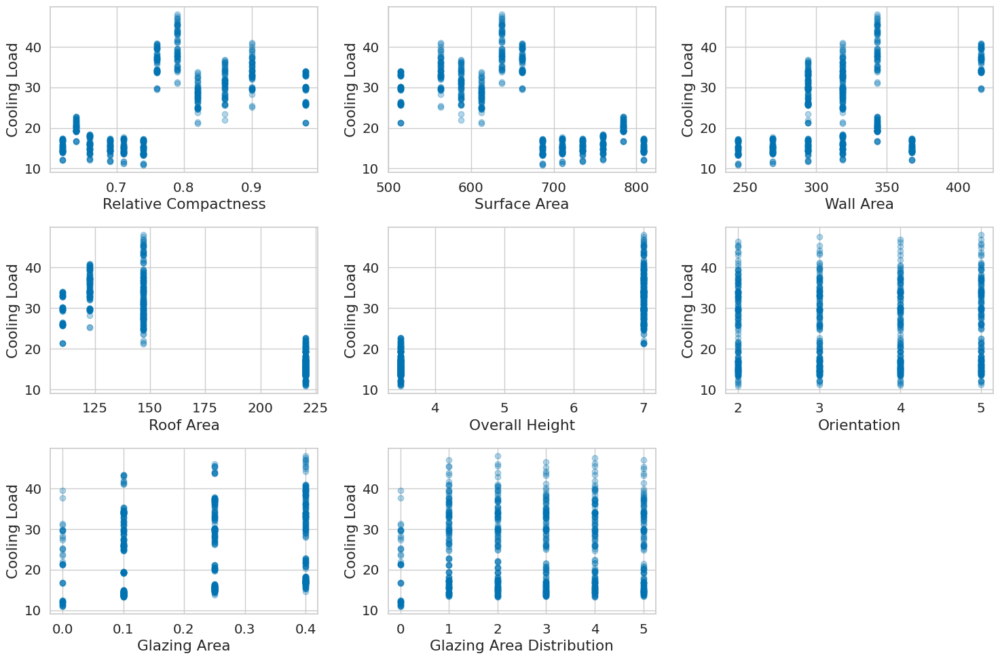

In [8]:
features = energy_X.columns

plt.figure(figsize=(15, 10))
for i, feature in enumerate(features, 1):
    plt.subplot(3, 3, i)
    plt.scatter(energy_X[feature], energy_y, alpha=0.3)
    plt.xlabel(feature)
    plt.ylabel(energy_y.name)
plt.tight_layout()
plt.show()

Как мы видим, некоторые признаки нелинейны, например, `Relatuve Compactness` и `Surface Area`. Также все признаки дискретны, а не континуальны, но при том  отклик на отдельных значениях имеет довольно большой разброс, как например, при значении `Roof Area` около 150. Всё это создаёт неудачные условия для использования линейной регрессии.

## <span style="display:inline-block;padding:2px 8px;border-radius:999px;background:linear-gradient(135deg, #C7480B 0%, #B52D59 54%, #A617B3 100%);color:#FFFFFF;font-size:0.78em;vertical-align:0.08em;">2</span> <span style="color:inherit;">Регрессия на нелинейных данных</span>

### <span style="display:inline-block;padding:2px 8px;border-radius:999px;background:linear-gradient(135deg, #C7480B 0%, #B52D59 54%, #A617B3 100%);color:#FFFFFF;font-size:0.78em;vertical-align:0.08em;">2.1</span> <span style="color:inherit;">Нелинейная зависимость</span>

Прежде чем использовать другие методы для задачи оценки затрат энергии, рассмотрим более простые данные &mdash; синтетические. Для этого создадим искусственный датасет с нелинейной зависимостью. Пусть он будет выражаться квадратичной функцией $-2 x^2$, при $x < 5$ и линейной функцией $3x$, при $x \ge 5$. Также добавим случайный шум $\varepsilon$, как в настоящих данных.

Итого данные описываются зависимостью  $y = -2x^2 I\{x < 5\} + 3x I\{x \ge 5\} + \varepsilon$.

In [1]:
def generate_non_linear_data(
    n_samples: int = 100, theta1: float = -2.0, theta2: float = 3.0, X_max: float = 10.0
) -> Tuple[np.ndarray, np.ndarray]:
    """
    Генерирует данные для нелинейной модели
    y = features^2 * theta1 * I {features < 5} + features * theta2 * I {features >= 5} + ε, где ε ~ N(0, 2).

    Параметры:
    n_samples (int): Количество выборок (по умолчанию 100).
    theta1 (float): Коэффициент для квадратичной зависимости (по умолчанию -2.0).
    theta2 (float): Коэффициент для линейной зависимости (по умолчанию 3.0).
    X_max (float): Максимальное значение для генерации features (по умолчанию 10.0).

    Возвращает:
    Tuple[np.ndarray, np.ndarray]: Кортеж из двух массивов numpy: features и target_values.
    """
    # Признаки
    features = np.random.uniform(low=0.0, high=1.0, size=(n_samples, 1)) * X_max
    # Генерация шума
    noise = np.random.normal(loc=0.0, scale=2.0, size=(n_samples, 1))

    # Вычисление target
    target_values = (
        features**2 * (features < 5.0) * theta1 + features * (features > 5.0) * theta2 + noise
    )

    return features, target_values

In [2]:
n_samples = 100  # количество элементов в выборке
grid_size = 1000  # точность сетки
theta1 = -2  # коэффициент для линейной зависимости
theta2 = 3  # коэффициент при sin(x)
X_max = 10  # максимальное значение X

X_grid = np.linspace(0, X_max, grid_size)  # равномерная сетка для X от 0 до X_max
f_grid = (
    X_grid**2 * (X_grid < 5.0) * theta1 + X_grid * (X_grid > 5.0) * theta2
)  # значение функции на сетке

X, y = generate_non_linear_data(
    n_samples=n_samples, theta1=theta1, theta2=theta2, X_max=X_max
)  # данные для обучения

NameError: name 'np' is not defined

И визуализируем данные.

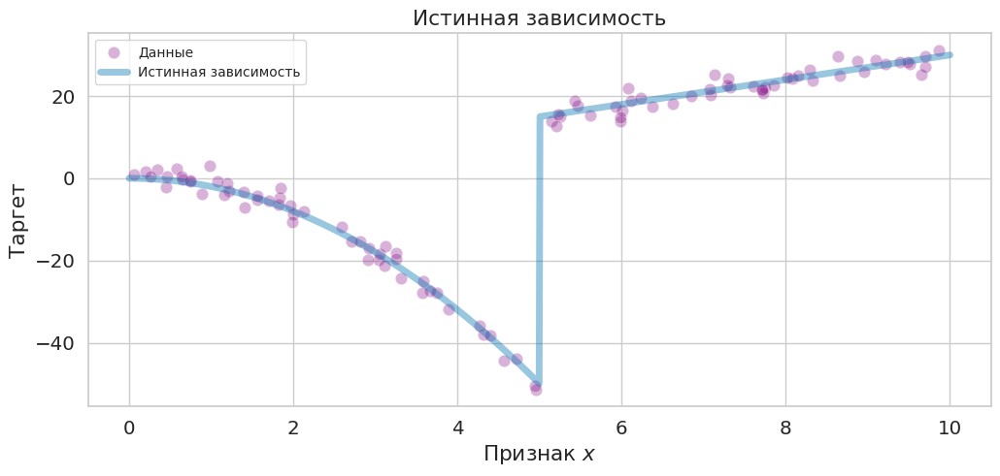

In [11]:
plot_regression_results(X, y, X_grid, f_grid, title="Истинная зависимость")

Для удобства сделаем функцию добавления параметра к обучению.

In [12]:
data = pd.DataFrame({})
data_grid = pd.DataFrame({})
model_preds = {}

In [13]:
def add_param_and_draw(param_name: str, param_func: Callable[[np.ndarray], np.ndarray]):
    """
    1. Добавляет признак к data и data_grid
    2. Обучает линейную регрессию на data
    3. Добавляем новые предсказания на data_grid в model_preds и отрисовываем

    Параметры:
    param_name (str): Название нового признака.
    param_func (Callable): Функция для преобразования признаков от X.
    """
    # формируем данные
    data[param_name] = param_func(X)
    data_grid[param_name] = param_func(X_grid)

    # обучаем модель
    model = LinearRegression()
    model.fit(data, y)

    # получаем предсказания
    model_preds[param_name] = model.predict(data_grid)
    # отрисовываем
    plot_regression_results(X, y, X_grid, f_grid, model_preds)

### <span style="display:inline-block;padding:2px 8px;border-radius:999px;background:linear-gradient(135deg, #C7480B 0%, #B52D59 54%, #A617B3 100%);color:#FFFFFF;font-size:0.78em;vertical-align:0.08em;">2.2</span> <span style="color:inherit;">Линейная регрессия</span>

Посмотрим на предсказание линейной регрессии.

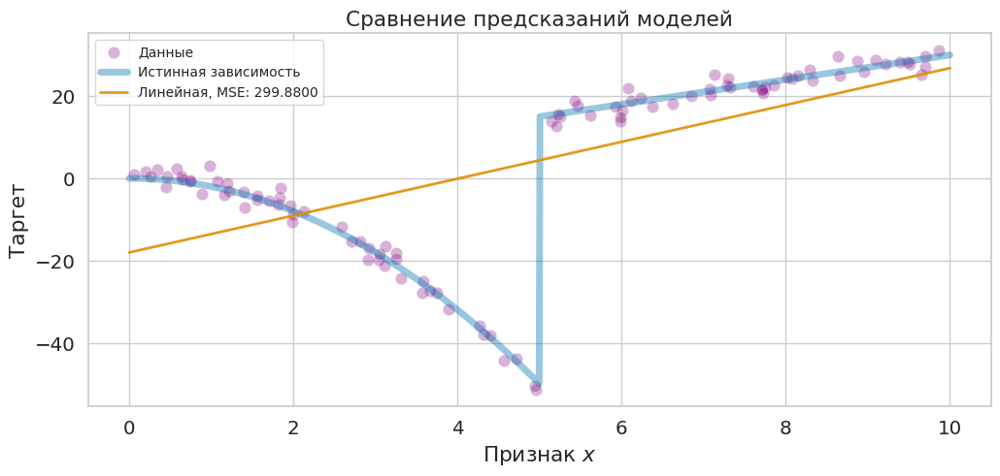

In [14]:
add_param_and_draw("Линейная", lambda x: x.flatten())

Добавим $x^2$ в качестве признака, чтобы линейная модель могла отлавливать квадратичную зависимость.

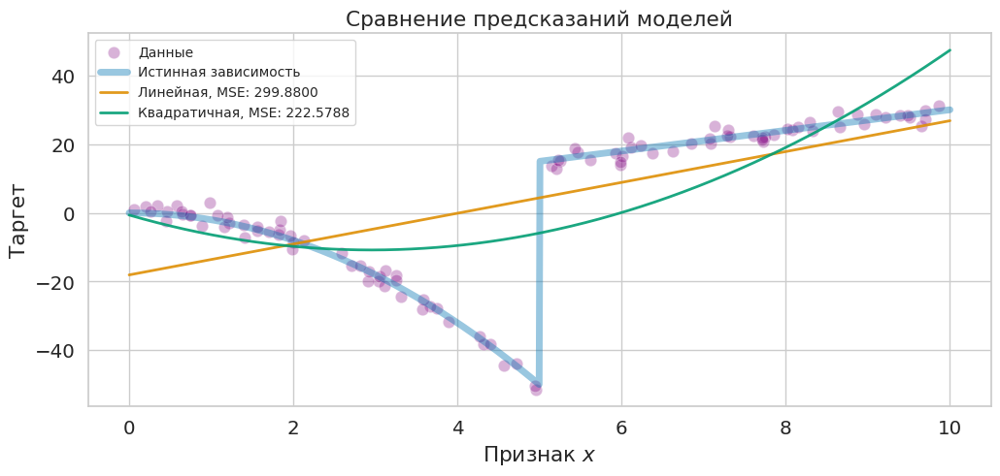

In [15]:
add_param_and_draw("Квадратичная", lambda x: x.flatten() ** 2)

Как видим, линейная регрессия порядка 2 представляет собой параболу и плохо приближает исходную зависимость. Теперь добавим $I\{x < 5\}$ в качестве признака

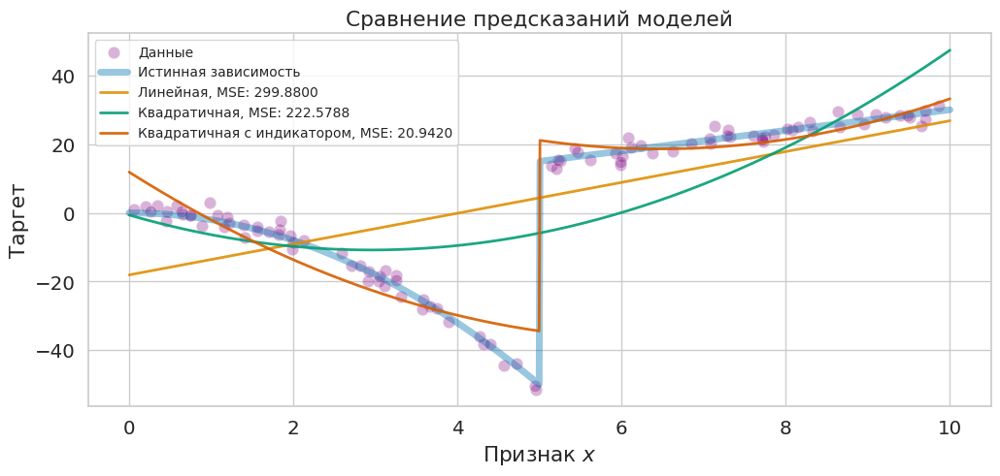

In [16]:
add_param_and_draw("Квадратичная с индикатором", lambda x: (x.flatten() < 5.0) * 1.0)

Мы получили параболу со сдвигом. Добавим теперь $x \cdot I\{x \ge 5\}$

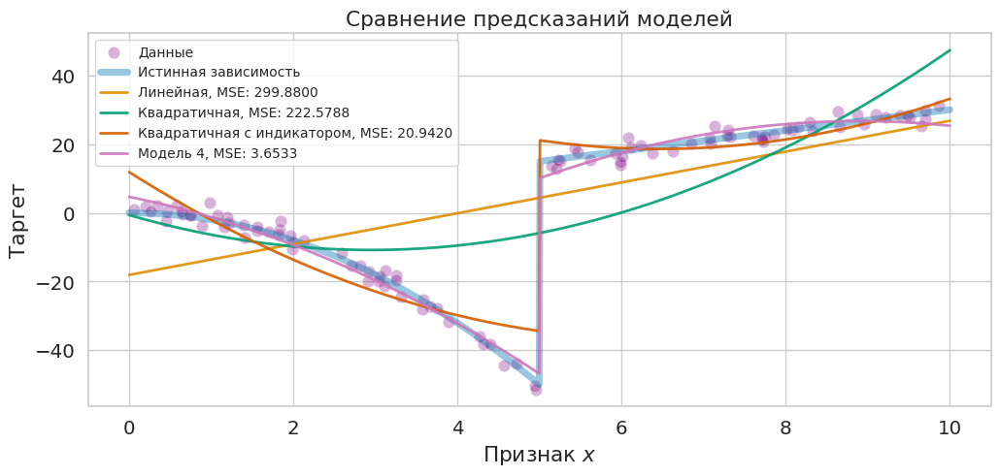

In [17]:
add_param_and_draw("Модель 4", lambda x: (x.flatten() >= 5.0) * x.flatten())

Добавим последний признак

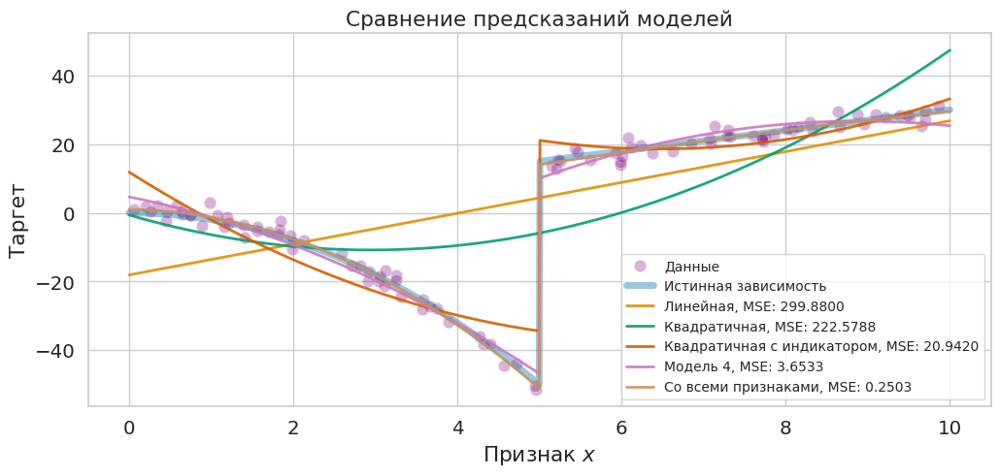

In [18]:
add_param_and_draw("Со всеми признаками", lambda x: (x.flatten() < 5.0) * x.flatten() ** 2)

Модель со всеми признаками довольно точно приблизила истинную зависимость. Но... На практике данные сложные, и глазами мы можем и не понять, каких признаков не хватает линейной модели. Воспользуемся другим методом решения задачи

### <span style="display:inline-block;padding:2px 8px;border-radius:999px;background:linear-gradient(135deg, #C7480B 0%, #B52D59 54%, #A617B3 100%);color:#FFFFFF;font-size:0.78em;vertical-align:0.08em;">2.3</span> <span style="color:inherit;">Решающие деревья для регрессии</span>

✍️ Вспомним материал лекции.

Пусть наши данные имеют вид $(X_1, Y_1), (X_2, Y_2) \dots (X_n, Y_n)$. Для пресказания $y$ по $x$ будем строить решающее дерево по следующему правилу:

1. **Начало.** На первом этапе построения дерева мы имеем один лист с меткой $\overline{Y}$, к нему относятся все объекты.
2. **Деление листа.**

    Пусть на очередном этапе $\mathcal{I}_{leaf}$ &mdash; индексы объектов в текущем рассматриваемом листе. Делим лист на два с подмножествами индексов $\mathcal{I}_{\ell} \sqcup \mathcal{I}_{r} = \mathcal{I}_{leaf}$ по следующему принципу.

    1. **Правило деления**
        
        $x_j < t \Rightarrow$ объект $x$ попадает в левое поддерево $\ell$, иначе в правое $r$.
	
    2. **Выбор правила:** наилучшее приближение двумя константами
	     	$$\sum_{i \in \mathcal{I}_{\ell}} (Y_i - y_\ell)^2 + \sum_{i \in \mathcal{I}_r} (Y_i - y_r)^2 \longrightarrow \min_{\mathcal{I}_{\ell}, \mathcal{I}_{r}}$$

    3. **Метки в новых листьях**
        $$\hspace{0.7cm}y_\ell = \frac{1}{|\mathcal{I}_\ell|} \sum_{i \in \mathcal{I}_\ell} Y_i, \;\;\;\;\; y_r = \frac{1}{|\mathcal{I}_r|} \sum_{i \in \mathcal{I}_r} Y_i$$


>
>Для работы с деревом будем использовать из `sklearn` два класса [`sklearn.tree.DecisionTreeRegressor`](https://scikit-learn.org/stable/modules/generated/sklearn.tree.DecisionTreeRegressor.html) и [`sklearn.tree.DecisionTreeClassifier`](https://scikit-learn.org/stable/modules/generated/sklearn.tree.DecisionTreeClassifier.html).
>
> **Важные аргументы конструктора:**
>*   `max_depth` &mdash; максимальная глубина дерева
>*   `min_samples_leaf` &mdash; минимальное возможное число элементов в листе
>*   `min_samples_split` &mdash; минимальное число элементов, при котором продолжаем деление вершины
>
>**Основные методы класса:**
>*   `fit(X, y)` &mdash; обучает дерево на выборке `X` и таргетах `y`
>*   `predict(X)` &mdash; предсказывает значения на выборке `X`

Теперь посмотрим предсказания деревьев и сравним с линейной регрессией, обученной на всех признаках

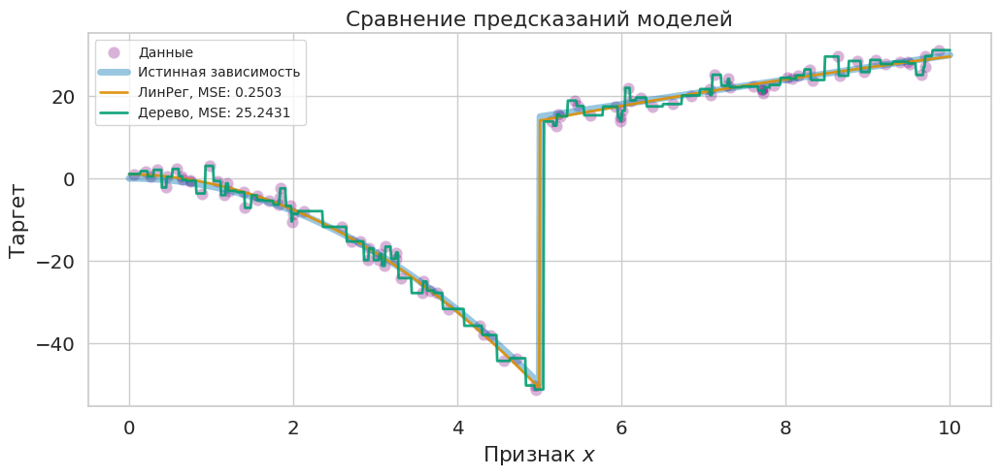

In [19]:
tree_model = DecisionTreeRegressor()
tree_model.fit(data.iloc[:, :1], y)

liner_model = LinearRegression()
liner_model.fit(data, y)

model_preds = {
    "ЛинРег": liner_model.predict(data_grid),
    "Дерево": tree_model.predict(data_grid.iloc[:, :1]),
}
plot_regression_results(X, y, X_grid, f_grid, model_preds)

Видно, что дерево приблизило исходную зависимость. Причём оно справляется с нелинейными зависимостями даже без дополнительных признаков. Однако, как мы видим на графике выше, модель чётко следует данным, а не предсказывает истинную зависимость.

<div style="box-sizing:border-box;max-width:100%;margin:14px 0 0;padding:0;border:1px solid rgba(199,50,78,0.20);border-bottom:0;border-radius:12px 12px 0 0;overflow:hidden;color:inherit;"><span style="display:inline-block;padding:4px 11px;border-radius:4px 12px 12px 4px;background:linear-gradient(135deg,#D4470E,#C7324E,#B316B8);color:white;font-size:10.5px;font-weight:800;letter-spacing:0.06em;text-transform:uppercase;white-space:nowrap;">Вопрос</span></div>

<div style="box-sizing:border-box;max-width:100%;padding:10px 14px 13px;border-left:1px solid rgba(199,50,78,0.20);border-right:1px solid rgba(199,50,78,0.20);border-bottom:1px solid rgba(199,50,78,0.20);border-radius:0 0 12px 12px;margin-bottom:8px;">

Как называется такая ситуация? Как мы можем повлиять на это?

</div>

<details style="box-sizing:border-box;max-width:100%;margin:0 0 18px;padding:8px 14px 10px;border:1px solid rgba(199,50,78,0.20);border-radius:10px;color:inherit;">

<summary style="cursor:pointer;color:inherit;font-size:13px;font-weight:750;text-decoration:underline;text-decoration-color:#C7324E;text-decoration-thickness:1.5px;text-underline-offset:3px;">Показать ответ</summary>

Дерево **переобучилось**. Чтобы избежать переобучения можно работать как с данными, например с помощью предобработки данных, так и с моделью, например настраивая гиперпараметры.

</details><br/>

Также мы можем заметить, что зависимость, которую восстанавливает дерево, "паралелльна" осям признаков. Другими словами, предсказания дерева образуют кусочно-постоянную ступенчатую функцию.

&#x2753; **Самое время задаться несколькими вопросами:** &#x2753;
>
>Как выглядит предсказание дерева?
>
>Как гиперпараметры влияют на предсказания?
>
>Какими выбрать эти гиперпараметры?

### <span style="display:inline-block;padding:2px 8px;border-radius:999px;background:linear-gradient(135deg, #C7480B 0%, #B52D59 54%, #A617B3 100%);color:#FFFFFF;font-size:0.78em;vertical-align:0.08em;">2.4</span> <span style="color:inherit;">Влияние гиперпараметров на предсказание</span>


У `DecisionTreeRegressor` есть несколько гиперпараметров, среди которых можно особо выделить:
- `max_depth` &mdash; максимальная глубина дерева.
- `min_samples_leaf` &mdash; минимальное возможное число элементов в листе
- `min_samples_split` &mdash; минимальное число элементов, при котором продолжаем деление вершины

Посмотрим на многомерные данные.

В целом, бывает полезно посмотреть на разделяющую поверхность. По виду разделяющей поверхности можно получить представление, действительно ли дерево улавливает важные закономерности в данных и не возникло ли переобучения. Если данные имеют большое число признаков, то визуализировать разделяющую поверхность довольно сложно.

Сгенирируем двумерные данные:

In [20]:
X, y = datasets.make_regression(
    n_samples=1000, n_features=2, noise=40, bias=10, random_state=RANDOM_STATE
)

Визуализируем. Таргет показан цветом точки.

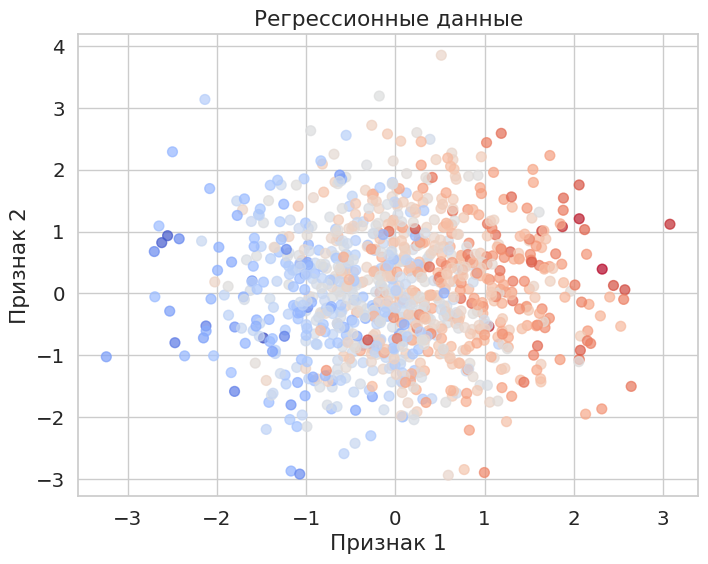

In [21]:
plt.figure(figsize=(8, 6))
grid_x1 = X[:, 0]
grid_x2 = X[:, 1]
plt.scatter(grid_x1, grid_x2, c=y, s=50, alpha=0.7, cmap="coolwarm")
plt.xlabel("Признак 1")
plt.ylabel("Признак 2")
plt.title("Регрессионные данные")
plt.show()

Разобъём на обучение и тест

In [22]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE)

animate_regression = partial(
    animate_decision_surface,
    DecisionTreeRegressor,
    X_train=X_train,
    y_train=y_train,
    X_test=X_test,
    y_test=y_test,
    random_state=RANDOM_STATE,
)

Напишем код отрисовки в виде анимации

#### <span style="display:inline-block;padding:2px 8px;border-radius:999px;background:linear-gradient(135deg, #C7480B 0%, #B52D59 54%, #A617B3 100%);color:#FFFFFF;font-size:0.78em;vertical-align:0.08em;">2.4.1</span> <span style="color:inherit;">Визуализация для `max_depth`</span>

Теперь попробуем посмотреть как будет меняться поверхность и $R^2$, при использовании различных `max_depth`.

`max_depth` &mdash; важный параметр решающего дерева. Вершина дерева может продолжать разбиение, только если её глубина меньше `max_depth`.

In [23]:
anim = animate_regression("max_depth", np.arange(1, 51))
HTML(anim.to_jshtml())

При `max_depth` > 4 метрика на обучающей выборке продолжила расти, а на тестовой выборке стала хуже. Это означает, что произошло **переобучение дерева**. Этот пример демонстрирует проявление на практике следующих свойств решающих деревьев:

1. Решающие деревья очень легко могут быть переобучены, причём склонность к переобучению возрастает с возрастанием глубины дерева.
2. Для решения задачи регрессии недостаточно малой глубины дерева, но при слишком большой глубине может происходить переобучение.

>_Замечание: Регрессионная зависимость, восстанавливаемая деревом, выглядит сильно сложно. Значит деревья лучше справляются с нелинейными зависимостями. И напротив плохо с линейными._

<div style="box-sizing:border-box;max-width:100%;margin:14px 0 0;padding:0;border:1px solid rgba(199,50,78,0.20);border-bottom:0;border-radius:12px 12px 0 0;overflow:hidden;color:inherit;"><span style="display:inline-block;padding:4px 11px;border-radius:4px 12px 12px 4px;background:linear-gradient(135deg,#D4470E,#C7324E,#B316B8);color:white;font-size:10.5px;font-weight:800;letter-spacing:0.06em;text-transform:uppercase;white-space:nowrap;">Вопрос</span></div>

<div style="box-sizing:border-box;max-width:100%;padding:10px 14px 13px;border-left:1px solid rgba(199,50,78,0.20);border-right:1px solid rgba(199,50,78,0.20);border-bottom:1px solid rgba(199,50,78,0.20);border-radius:0 0 12px 12px;margin-bottom:8px;">

Почему деревья плохо справляются с линейными зависимостями?

</div>

<details style="box-sizing:border-box;max-width:100%;margin:0 0 18px;padding:8px 14px 10px;border:1px solid rgba(199,50,78,0.20);border-radius:10px;color:inherit;">

<summary style="cursor:pointer;color:inherit;font-size:13px;font-weight:750;text-decoration:underline;text-decoration-color:#C7324E;text-decoration-thickness:1.5px;text-underline-offset:3px;">Показать ответ</summary>

Как мы уже заметили, деревья разбивают пространство признаков **по порогам вдоль отдельных признаков**, формируя прямоугольные области, параллельные осям координат. Поэтому в задачах с выраженной линейной зависимостью (например, $y = 3x + 5$), дерево решений будет пытаться аппроксимировать её **ступенчато**, последовательно разделяя область признаков на интервалы.
 Это приводит к:

- необходимости большой глубины дерева;
- появлению артефактов в предсказаниях;
- переобучению, если данные шумные.

Таким образом, при линейных зависимостях **линейные модели** (например, `LinearRegression`) предпочтительнее, а деревья — избыточны и неэффективны.

>_Замечание: Есть также продвинутый подход к проблеме. Так в [этой статье](https://www.researchgate.net/publication/2640479_Employing_Linear_Regression_in_Regression_Tree_Leaves) и некоторых других рассматривается модификация дерева, при котором в каждом его листе для предсказания обучается линейная регрессия. Также есть [реализация](https://github.com/cerlymarco/linear-tree) этой идеи._

</details><br/>

**Вывод.**

Как правило
* увеличение значения параметра `max_depth` приводит к увеличению точности классификации на обучающей выборке,
* но с некоторого момента увеличение значения `max_depth` приводит к ухудшению точности на тестовой выборке, так как начинается стадия переобучения.

#### <span style="display:inline-block;padding:2px 8px;border-radius:999px;background:linear-gradient(135deg, #C7480B 0%, #B52D59 54%, #A617B3 100%);color:#FFFFFF;font-size:0.78em;vertical-align:0.08em;">2.4.2</span> <span style="color:inherit;">Визуализация для `min_samples_leaf`</span>

Другим важным параметром решающего дерева является `min_samples_leaf` — минимальное количество объектов, которое должно оказаться в каждом листе дерева. При попытке разделить вершину дерево проверяет: достаточно ли объектов попадёт в каждый из дочерних листов. Если в какой-либо из них попадёт меньше, чем `min_samples_leaf`, то разбиение не выполняется.

Это ограничение необходимо для того, чтобы предсказания в листах были **устойчивыми**. Если в лист попадает всего один объект, предсказание модели будет точно совпадать с его целевым значением — а это делает модель чувствительной к шуму. Если же в листе, например, 5 объектов, предсказание будет усреднённым и менее подвержено выбросам. Кроме того, без этого ограничения возможна ситуация, когда один "выбросный" объект определяет поведение модели в целой области признакового пространства — даже если он находится на его краю.


In [24]:
anim = animate_regression("min_samples_leaf", np.arange(1, 41))
HTML(anim.to_jshtml())

Мы видим, что в задаче регрессии `min_samples_leaf` лучше делать не большим. Этим параметром мы упрощаем решающую область, а как следствие регрессия становится менее точной.

#### <span style="display:inline-block;padding:2px 8px;border-radius:999px;background:linear-gradient(135deg, #C7480B 0%, #B52D59 54%, #A617B3 100%);color:#FFFFFF;font-size:0.78em;vertical-align:0.08em;">2.4.3</span> <span style="color:inherit;">Другие параметры.</span>

Кроме того, обратите внимание на другие параметры класса `DecisionTreeRegressor` в `sklearn`:

1. `criterion` &mdash; критерий, по которому происходит разбиение вершины дерева. Стандартные критерии для классификации &mdash; критерий Джини (`giny`) и энтропийный критерий (`entropy`), при этом `giny` &mdash; критерий по умолчанию.  В этом ноутбуке мы брали для классификации критерий по умолчанию.  Более подробную информацию по критериям можно найти в <a href="https://scikit-learn.org/stable/modules/generated/sklearn.tree.DecisionTreeRegressor.html" target="_blank">документации sklearn</a>.


2. `splitter` &mdash; способ разбиения вершины решающего дерева. Есть два возможных варианта: `best` и `random`. В первом случае рассматриваются все возможные способы разбить вершину дерева на две и берётся тот из них, значение критерия для которого оптимально. При `splitter=random` берётся несколько случайных возможных разбиений и среди них выбирается то, значение критерия для которого оптимально.


3. `max_features` &mdash; максимальное количество признаков, которые могут быть перебраны при разбиении вершины дерева. Перед каждым разбиением вершины генерируется выборка из `min(d, max_features)` случайных признаков (`d` &mdash; количество признаков в датасете) и только эти признаки рассматриваются как разделяющие.


4. `min_impurity_decrease` &mdash; минимальное значение уменьшения взвешенного критерия неопределенности (`impurity`), чтобы можно было разбить выборку в данной вершине.


Об остальных гиперпараметрах класса решающего дерева в `sklearn` можно прочитать в <a href="https://scikit-learn.org/stable/modules/generated/sklearn.tree.DecisionTreeRegressor.html" target="_blank">документации</a>.

### <span style="display:inline-block;padding:2px 8px;border-radius:999px;background:linear-gradient(135deg, #C7480B 0%, #B52D59 54%, #A617B3 100%);color:#FFFFFF;font-size:0.78em;vertical-align:0.08em;">2.5</span> <span style="color:inherit;">График зависимости метрики от гиперпараметров</span>

Вернёмся к исходной задаче про энергоэффективность. Если использовать дерево бездумно получится не очень хорошо:

In [25]:
X_train, X_test, y_train, y_test = train_test_split(
    energy_X, energy_y, test_size=0.2, random_state=RANDOM_STATE
)

In [26]:
tree_energy = DecisionTreeRegressor(random_state=RANDOM_STATE)
tree_energy.fit(X_train, y_train)

for name, metric in zip(
    ["r2_score", "MSE", "MAE", "MAPE"],
    [r2_score, mean_squared_error, mean_absolute_error, mean_absolute_percentage_error],
):
    print("train {} {:.4f}".format(name, metric(y_train, tree_energy.predict(X_train))))
    print("test {} {:.4f}\n".format(name, metric(y_test, tree_energy.predict(X_test))))

train r2_score 1.0000
test r2_score 0.9561

train MSE 0.0000
test MSE 4.0692

train MAE 0.0000
test MAE 1.1551

train MAPE 0.0000
test MAPE 0.0406



Мы переобучились! На обучении у нас 100% точность! Что будем делать? Настраивать гиперпараметры.

---



Смотреть на разделяющую поверхность при таком количестве признаков проблематично. Пора разработать первую стратегию подбора гиперпараметров, для любого количества признаков.

Построим график зависимости метрики $R^2$ и MSE от гипперпараметров на обучающей и на тестовой выборках.

Идея простая:
1. Сделаем сетку по параметру.
2. Для каждого значения обучим дерево и посчитаем значение метрики на тесте.
3. Построим график зависимости.

Реализуем вспомогательные функции

In [27]:
def get_train_and_test_regression_scores(param_name: str, grid: np.ndarray):
    """
    Функция для оценки качества регрессии
    для заданных значений параметра param_name

    Параметры:
    param_name (str) - название параметра, который собираемся варьировать,
    grid (np.ndarray) - сетка значений параметра
    """

    train_metrics, test_metrics = [], []

    for param_value in grid:
        estimator = DecisionTreeRegressor(**{param_name: param_value})
        estimator.fit(X_train, y_train)
        train_metrics.append(
            [
                r2_score(y_train, estimator.predict(X_train)),
                mean_squared_error(y_train, estimator.predict(X_train)),
            ]
        )
        test_metrics.append(
            [
                r2_score(y_test, estimator.predict(X_test)),
                mean_squared_error(y_test, estimator.predict(X_test)),
            ]
        )
    return np.array(train_metrics), np.array(test_metrics)

Для начала посмотрим на график зависимости от `max_depth`

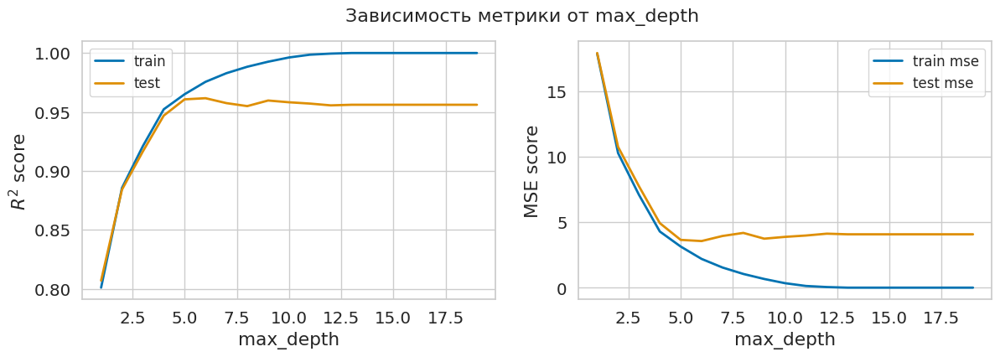

In [28]:
plot_dependence(
    "max_depth",
    range(1, 20),
    title="Зависимость метрики от max_depth",
    score=get_train_and_test_regression_scores,
)

По графику видно, что с ростом глубины $R^2$ score приближается к 1 на обучающей выборке. Более того, можно сделать вывод, что для выборки существует **решающее дерево, идеально восстанавливающее истинный отклик.** Такое дерево будет **переобучено**. Также заметим, что качество на тесте растёт до некоторого момента, но потом падает.

MSE соответственно уменьшается и стремиться к 0.

Лучшее значение `max_depth` = 6.

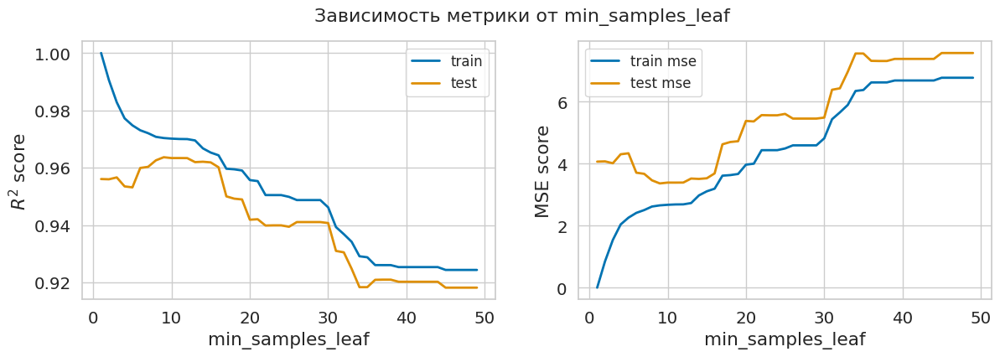

In [29]:
plot_dependence(
    "min_samples_leaf",
    range(1, 50),
    title="Зависимость метрики от min_samples_leaf",
    score=get_train_and_test_regression_scores,
)

На графике наглядно видно, что оптимальное значение `min_samples_leaf` = 9. Не трудно заметить, что с его ростом качество модели падает.

>*Замечание: Если подбирать значения гиперпараметров на обучающей выборке, то качество предсказаний на новых данных начнёт падать.*

Обучим дерево на полученных оптимальных параметрах

In [30]:
best_tree_energy = DecisionTreeRegressor(random_state=RANDOM_STATE, max_depth=6, min_samples_leaf=9)
best_tree_energy.fit(X_train, y_train)

for name, metric in zip(
    ["r2_score", "MSE", "MAE", "MAPE"],
    [r2_score, mean_squared_error, mean_absolute_error, mean_absolute_percentage_error],
):
    print("train {} {:.4f}".format(name, metric(y_train, best_tree_energy.predict(X_train))))
    print("test {} {:.4f}\n".format(name, metric(y_test, best_tree_energy.predict(X_test))))

train r2_score 0.9692
test r2_score 0.9621

train MSE 2.7640
test MSE 3.5153

train MAE 1.0862
test MAE 1.2306

train MAPE 0.0394
test MAPE 0.0414



Сравним результаты трёх моделей: линейной регрессии и деревьев с дефолтными и с подобранными гиперпараметрами

In [31]:
result_df = pd.DataFrame(
    columns=[
        "Модель",
        "R2 (train)",
        "R2 (test)",
        "MSE (train)",
        "MSE (test)",
        "MAE (train)",
        "MAE (test)",
        "MAPE (train)",
        "MAPE (test)",
    ]
)
result_df.loc[0] = ["Линейная Регрессия"] + calc_metrics(
    linear_energy, X_train, y_train, X_test, y_test
)
result_df.loc[1] = ["Дерево без настройки"] + calc_metrics(
    tree_energy, X_train, y_train, X_test, y_test
)
result_df.loc[2] = ["Дерево с настройками"] + calc_metrics(
    best_tree_energy, X_train, y_train, X_test, y_test
)

visualize_metric_df(result_df, 3)

,Модель,R2 (train),R2 (test),MSE (train),MSE (test),MAE (train),MAE (test),MAPE (train),MAPE (test)
0,Линейная Регрессия,0.886,0.893,10.228,9.893,2.253,2.195,0.090,0.085
1,Дерево без настройки,1.000,0.956,0.000,4.069,0.000,1.155,0.000,0.041
2,Дерево с настройками,0.969,0.962,2.764,3.515,1.086,1.231,0.039,0.041


**Вывод:**

Мы смогли обучить дерево, которое работает лучше линейной регрессии в данной задаче и показывает лучшее качество.

Однако, чтобы дерево не переобучалось, нужно подбирать его гиперпараметры под конкретные данные. Таким образом, потеряв качество на обучающей выборке, модель лучше предсказывает на тестовых данных, что на практике и необходимо.

## <span style="display:inline-block;padding:2px 8px;border-radius:999px;background:linear-gradient(135deg, #C7480B 0%, #B52D59 54%, #A617B3 100%);color:#FFFFFF;font-size:0.78em;vertical-align:0.08em;">3</span> <span style="color:inherit;">Визуализация решающих деревьев</span>

Посмотрим, как можно визуализировать структуру решающего дерева, в этом нам поможет библиотека `graphviz`.

Для установки библиотеки через pip:
```bash
pip install graphiz
```

Для установки библиотеки через conda:
```bash
conda install -c conda-forge python-graphiz
```

Визуализируем дерево, полученное из оптимальных гиперпараметров для задачи об оценке энергоэффективности домов.

Напишем функцию визуализации дерева

In [32]:
def get_graphviz_graph(decision_tree_regressor: DecisionTreeRegressor):
    """
    Функция для обучения решающего дерева и построения
    по нему графа graphviz для визуализации
    """

    decision_tree_regressor.fit(X_train, y_train)

    dot_data = export_graphviz(
        decision_tree_regressor,
        out_file=None,
        feature_names=energy_X.columns,
        class_names=["G3"],
        filled=True,
        rounded=True,
        special_characters=True,
    )
    return graphviz.Source(dot_data)

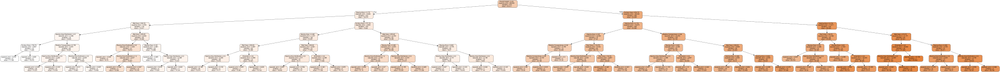

In [33]:
regressor = DecisionTreeRegressor(max_depth=6, min_samples_split=9)
graph = get_graphviz_graph(regressor)
graph

Визуализируем деревья для разной глубины

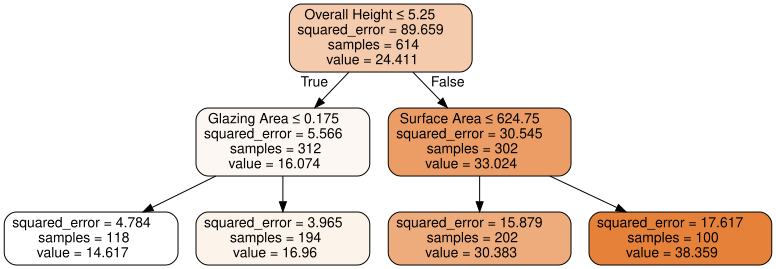

In [34]:
regressor = DecisionTreeRegressor(max_depth=2, min_samples_split=9)
graph = get_graphviz_graph(regressor)
graph

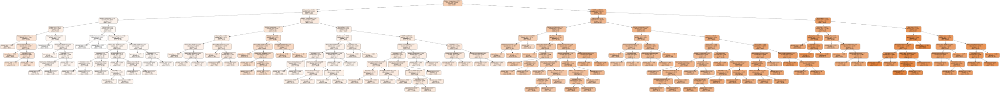

In [35]:
regressor = DecisionTreeRegressor(max_depth=10, min_samples_split=9)
graph = get_graphviz_graph(regressor)
graph

По построенной визуализации дерева можно увидеть, что большая часть разбиений вершин вполне соотносится со здравым смыслом и логикой принятия решений человеком. Например, прежде всего дерево ориентируется на `Relative Compactness` &mdash; оценку компактности. После на признаки остеклённости `Glazing Area` и `Glazing Area Distribution`.

## <span style="display:inline-block;padding:2px 8px;border-radius:999px;background:linear-gradient(135deg, #C7480B 0%, #B52D59 54%, #A617B3 100%);color:#FFFFFF;font-size:0.78em;vertical-align:0.08em;">4</span> <span style="color:inherit;">Классификация</span>

В данном разделе познакомимся с решением задачи классификации с помощью деревьев. Рассмотрим похожим образом влияние гиперпараметров на качество классификации. Для наглядности в качестве датасета будем использовать `Iris`.

Датасет **Iris (Ирисы Фишера)** — один из самых известных и простых в машинном обучении. Он содержит 150 наблюдений об измерениях цветков трёх видов ирисов: *setosa*, *versicolor* и *virginica*. Каждый экземпляр описан четырьмя числовыми признаками: длина и ширина лепестка (`petal length`, `petal width`) и длина и ширина чашелистика (`sepal length`, `sepal width`), измеренными в сантиметрах.

Задача, как правило, заключается в классификации вида цветка по этим признакам. Датасет хорошо сбалансирован (по 50 экземпляров каждого вида), не содержит пропущенных значений и идеально подходит для обучения и тестирования методов классификации и визуализации решающих поверхностей.


In [36]:
iris = datasets.load_iris()
X = iris.data
y = iris.target

# variable information
print(iris.feature_names)
print(iris.target_names)

['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
['setosa' 'versicolor' 'virginica']


Разобьём данные на обучающую и тестовую выборки.

In [37]:
X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=RANDOM_STATE)

### <span style="display:inline-block;padding:2px 8px;border-radius:999px;background:linear-gradient(135deg, #C7480B 0%, #B52D59 54%, #A617B3 100%);color:#FFFFFF;font-size:0.78em;vertical-align:0.08em;">4.1</span> <span style="color:inherit;">Использование дерева без настройки</span>

Посмотрим на качество дефолтного дерева. Для классификации будем использовать класс `DecisionTreeClassifier`. Он имеет те же гиперпараметры и методы, что и регрессионная модель

<div style="box-sizing:border-box;max-width:100%;margin:14px 0 0;padding:0;border:1px solid rgba(199,50,78,0.20);border-bottom:0;border-radius:12px 12px 0 0;overflow:hidden;color:inherit;"><span style="display:inline-block;padding:4px 11px;border-radius:4px 12px 12px 4px;background:linear-gradient(135deg,#D4470E,#C7324E,#B316B8);color:white;font-size:10.5px;font-weight:800;letter-spacing:0.06em;text-transform:uppercase;white-space:nowrap;">Вопрос</span></div>

<div style="box-sizing:border-box;max-width:100%;padding:10px 14px 13px;border-left:1px solid rgba(199,50,78,0.20);border-right:1px solid rgba(199,50,78,0.20);border-bottom:1px solid rgba(199,50,78,0.20);border-radius:0 0 12px 12px;margin-bottom:8px;">

В чём тогда различие `DecisionTreeClassifier` и `DecisionTreeRegressor`?

</div>

<details style="box-sizing:border-box;max-width:100%;margin:0 0 18px;padding:8px 14px 10px;border:1px solid rgba(199,50,78,0.20);border-radius:10px;color:inherit;">

<summary style="cursor:pointer;color:inherit;font-size:13px;font-weight:750;text-decoration:underline;text-decoration-color:#C7324E;text-decoration-thickness:1.5px;text-underline-offset:3px;">Показать ответ</summary>

Различие в формировании предсказания. В задаче регрессии предсказание соответствует среднему таргету элементов в листе. $$\frac{1} {|\mathcal{I}|}\sum_{i \in \mathcal{I}} Y_i.$$ А для классификации &mdash; наиболее встречающемуся классу. $$\arg\max_{y \in \mathcal{Y}} \sum_{j\in \mathcal{I}} I\{Y_j = y\}.$$

</details><br/>

In [38]:
tree_classifier = DecisionTreeClassifier()
tree_classifier.fit(X_train, y_train)

print("train accuracy {:.4f}".format(accuracy_score(tree_classifier.predict(X_train), y_train)))
print("test accuracy {:.4f}".format(accuracy_score(tree_classifier.predict(X_test), y_test)))

train accuracy 1.0000
test accuracy 1.0000


Как мы видим дерево отлично справилось с простыми данными.

### <span style="display:inline-block;padding:2px 8px;border-radius:999px;background:linear-gradient(135deg, #C7480B 0%, #B52D59 54%, #A617B3 100%);color:#FFFFFF;font-size:0.78em;vertical-align:0.08em;">4.2</span> <span style="color:inherit;">Визуализация решающей поверхности в задаче классификации</span>

Также рассмотрим подпространство, образованное признаками `sepal length` и `petal width`.

In [39]:
X_sub_train = X_train[:, [0, 3]]
X_sub_test = X_test[:, [0, 3]]

animate_classification = partial(
    animate_decision_surface,
    DecisionTreeClassifier,
    X_train=X_sub_train,
    y_train=y_train,
    X_test=X_sub_test,
    y_test=y_test,
    random_state=RANDOM_STATE,
    step=0.05,
    metrics=[accuracy_score],
    param1="sepal length",
    param2="petal width",
)

#### <span style="display:inline-block;padding:2px 8px;border-radius:999px;background:linear-gradient(135deg, #C7480B 0%, #B52D59 54%, #A617B3 100%);color:#FFFFFF;font-size:0.78em;vertical-align:0.08em;">4.2.1</span> <span style="color:inherit;">Визуализация для `max_depth` &mdash; максимальная глубина дерева</span>

In [40]:
anim = animate_classification("max_depth", np.arange(1, 41))
HTML(anim.to_jshtml())

Можно заметить те же закономерности, что и при задаче регрессии. Также при большой глубине наша модель **переобучается.**

Также отдельно посмотрим на разделяющую поверхность при `max_depth = 1`. Она оказалась довольно простой. Ведь если глубина дерева равна одному, то в нём происходит разделение выборки ровно по одному признаку.

Несложно заметить, что если в датасете **для классификации $k$ классов, то необходимо брать дерево с глубиной не менее $\log_2 k$**, так как мы хотим, чтобы в полученном дереве было не менее $k$ листьев. Иначе дерево будет предсказывать $< k$ классов, чего мы хотим избежать.

#### <span style="display:inline-block;padding:2px 8px;border-radius:999px;background:linear-gradient(135deg, #C7480B 0%, #B52D59 54%, #A617B3 100%);color:#FFFFFF;font-size:0.78em;vertical-align:0.08em;">4.2.2</span> <span style="color:inherit;">Визуализация для `min_samples_leaf` &mdash; минимальное число элементов в листе</span>

In [41]:
anim = animate_classification("min_samples_leaf", np.arange(1, 51))
HTML(anim.to_jshtml())

В случае классификации при увеличении `min_sample_leaf` решающая поверхность также упрощается, но в данном случае это идёт на пользу модели и позволяет избегать переобучения (посмотрите на красный класс в скоплении белого).

Получается, увеличение значения параметра `min_samples_leaf` &mdash; один из способов борьбы с переобучением при использовании решающих деревьев. Но нужно быть осторожным с формой решающей поверхности.

#### <span style="display:inline-block;padding:2px 8px;border-radius:999px;background:linear-gradient(135deg, #C7480B 0%, #B52D59 54%, #A617B3 100%);color:#FFFFFF;font-size:0.78em;vertical-align:0.08em;">4.2.3</span> <span style="color:inherit;">Визуализация для `min_samples_split` &mdash; минимальное число элементов в листе, который будет делиться</span>

Последний параметр, который мы будем подробно визуализировать &mdash; `min_samples_split`.

In [42]:
anim = animate_classification("min_samples_split", np.arange(2, 51))
HTML(anim.to_jshtml())

**Вывод.**

При изменении значения `min_samples_split` происходит ситуация, аналогичной случаю, когда мы варьируем `min_samples_leaf`. И здесь наблюдается следующая закономерность: с увеличением значения `min_samples_split` качество
* на обучающей выборке падает,
* на тестовой выборке &mdash; до некоторого момента возрастает.

Кроме того, с увеличением `min_samples_split` разделяющая поверхность становится проще.

### <span style="display:inline-block;padding:2px 8px;border-radius:999px;background:linear-gradient(135deg, #C7480B 0%, #B52D59 54%, #A617B3 100%);color:#FFFFFF;font-size:0.78em;vertical-align:0.08em;">4.3</span> <span style="color:inherit;">График зависимости метрики от гиперпараметров</span>

In [43]:
def get_train_and_test_accuracy_score(param_name: str, grid: np.ndarray):
    """
    Функция для оценки точности классификации
    для заданных значений параметра param_name

    Параметры:
    param_name (str) - название параметра, который собираемся варьировать,
    grid (np.ndarray) - сетка значений параметра
    """

    train_acc, test_acc = [], []

    for param_value in grid:
        estimator = DecisionTreeClassifier(**{param_name: param_value})
        estimator.fit(X_train, y_train)
        train_acc.append(accuracy_score(y_train, estimator.predict(X_train)))
        test_acc.append(accuracy_score(y_test, estimator.predict(X_test)))
    return train_acc, test_acc

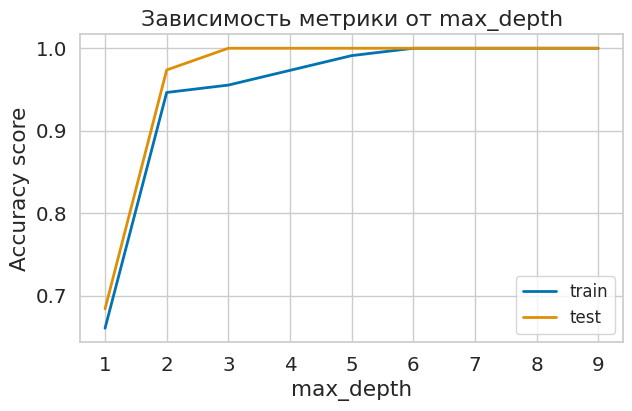

In [44]:
plot_classification_dependence(
    "max_depth",
    range(1, 10),
    title="Зависимость метрики от max_depth",
    score=get_train_and_test_accuracy_score,
)

**Вывод.**

Как видим, для данной выборки дерево не переобучается с ростом `max_depth`. Но достаточно взять дерево глубиной 6, чтобы получить оптимальное дерево.

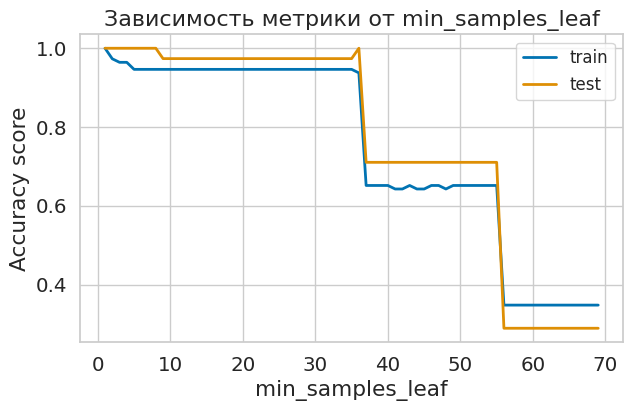

In [45]:
plot_classification_dependence(
    "min_samples_leaf",
    range(1, 70),
    title="Зависимость метрики от min_samples_leaf",
    score=get_train_and_test_accuracy_score,
)

**Вывод.**

По графику видно, что обобщающая способность решающего дерева начинает падать при `min_samples_leaf > 6`.

В целом наблюдается следующая закономерность. С увеличением значения `min_samples_leaf` качество
* на обучающей выборке падает,
* на тестовой выборке сначала возрастает, а затем начинает убывать.

Но, всё же, стоит заметить, что повышение значения `min_samples_leaf` делает разделяющую поверхность проще. Значит, при слишком больших значениях `min_samples_leaf` модель становится слишком простой и перестаёт улавливать закономерности из данных.

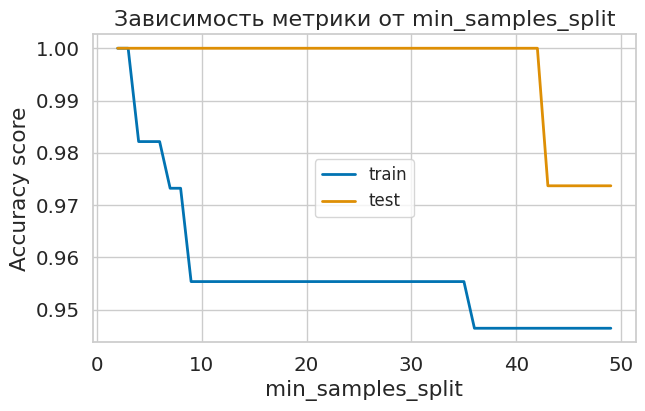

In [46]:
plot_classification_dependence(
    "min_samples_split",
    grid=range(2, 50),
    title="Зависимость метрики от min_samples_split",
    score=get_train_and_test_accuracy_score,
)

**Вывод.**

Значение accuracy на `train` монотонно падает с ростом `mean_samples_split`, а значение accuracy на `test` стабилизируется до некоторого момента.

## Заключение

Мы рассмотрели работу решающего дерева, как его предсказания зависят от выбора гиперпараметров и научились подбирать гиперпараметры под конкретную задачу. Дерево можно использовать как для задачи регрессии, так и при классификации.

Также мы научились отрисовывать полученное дерево.

<div style="box-sizing:border-box;max-width:100%;margin-top:42px;padding:18px 0 4px;border-top:1px solid rgba(127, 127, 127, 0.28);color:inherit;font-size:0.9em;line-height:1.5;"><img src="https://thetahat.ru/images/logo_thetahat.png" alt="ThetaHat" style="display:block!important;width:34px!important;max-width:34px!important;height:auto!important;margin:0 0 9px 0!important;padding:0!important;">© 2026 команда <a href="https://thetahat.ru/" style="color:inherit;font-weight:750;text-decoration:underline;text-decoration-color:#F13A3F;text-underline-offset:3px;">ThetaHat</a> для ШАД</div>